### Introduction
In this tutorial, we'll analyze the StackOverflow developer survey dataset. The dataset contains responses to an annual survey conducted by StackOverflow. You can find the raw data & official analysis here: https://insights.stackoverflow.com/survey.

There are several options for getting the dataset into Jupyter:

Download the CSV manually and upload it via Jupyter's GUI

Use the urlretrieve function from the urllib.request to download CSV 
files from a raw URL

Use a helper library, e.g., opendatasets, which contains a collection 
of curated datasets and provides a helper function for direct download.

We'll use the opendatasets helper library to download the files.

In [135]:
import opendatasets as od
od.download('stackoverflow-developer-survey-2020')

Using downloaded and verified file: .\stackoverflow-developer-survey-2020\survey_results_public.csv
Using downloaded and verified file: .\stackoverflow-developer-survey-2020\survey_results_schema.csv
Using downloaded and verified file: .\stackoverflow-developer-survey-2020\README.txt


In [136]:
import os

In [137]:
os.listdir('./stackoverflow-developer-survey-2020')

['README.txt', 'survey_results_public.csv', 'survey_results_schema.csv']

You can through the downloaded files using the "File" > "Open" menu option in Jupyter. It seems like the dataset contains three files:


README.txt - Information about the dataset

survey_results_schema.csv - The list of questions, and shortcodes for each 
question

survey_results_public.csv - The full list of responses to the questions

Let's load the CSV files using the Pandas library. We'll use the name survey_raw_df for the data frame to indicate this is unprocessed data that we might clean, filter, and modify to prepare a data frame ready for analysis.

In [138]:
import pandas as pd
survey_raw_df = pd.read_csv('./stackoverflow-developer-survey-2020/survey_results_public.csv')

In [139]:
survey_raw_df

,Respondent,MainBranch,Hobbyist,Age,Age1stCode,CompFreq,CompTotal,ConvertedComp,Country,CurrencyDesc,...,SurveyEase,SurveyLength,Trans,UndergradMajor,WebframeDesireNextYear,WebframeWorkedWith,WelcomeChange,WorkWeekHrs,YearsCode,YearsCodePro
0,1,I am a developer by profession,Yes,NaN,13,Monthly,NaN,NaN,Germany,European Euro,...,Neither easy nor difficult,Appropriate in length,No,"Computer science, computer engineering, or sof...",ASP.NET Core,ASP.NET;ASP.NET Core,Just as welcome now as I felt last year,50.0,36,27
1,2,I am a developer by profession,No,NaN,19,NaN,NaN,NaN,United Kingdom,Pound sterling,...,NaN,NaN,NaN,"Computer science, computer engineering, or sof...",NaN,NaN,Somewhat more welcome now than last year,NaN,7,4
2,3,I code primarily as a hobby,Yes,NaN,15,NaN,NaN,NaN,Russian Federation,NaN,...,Neither easy nor difficult,Appropriate in length,NaN,NaN,NaN,NaN,Somewhat more welcome now than last year,NaN,4,NaN
3,4,I am a developer by profession,Yes,25.0,18,NaN,NaN,NaN,Albania,Albanian lek,...,NaN,NaN,No,"Computer science, computer engineering, or sof...",NaN,NaN,Somewhat less welcome now than last year,40.0,7,4
4,5,"I used to be a developer by profession, but no...",Yes,31.0,16,NaN,NaN,NaN,United States,NaN,...,Easy,Too short,No,"Computer science, computer engineering, or sof...",Django;Ruby on Rails,Ruby on Rails,Just as welcome now as I felt last year,NaN,15,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64456,64858,NaN,Yes,NaN,16,NaN,NaN,NaN,United States,NaN,...,NaN,NaN,NaN,"Computer science, computer engineering, or sof...",NaN,NaN,NaN,NaN,10,Less than 1 year
64457,64867,NaN,Yes,NaN,NaN,NaN,NaN,NaN,Morocco,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64458,64898,NaN,Yes,NaN,NaN,NaN,NaN,NaN,Viet Nam,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64459,64925,NaN,Yes,NaN,NaN,NaN,NaN,NaN,Poland,NaN,...,NaN,NaN,NaN,NaN,Angular;Angular.js;React.js,NaN,NaN,NaN,NaN,NaN


The dataset contains over 64,000 responses to 60 questions (although many questions are optional). The responses have been anonymized to remove personally identifiable information, and each respondent has been assigned a randomized respondent ID.

Let's view the list of columns in the data frame.

In [140]:
survey_raw_df.columns

Index(['Respondent', 'MainBranch', 'Hobbyist', 'Age', 'Age1stCode', 'CompFreq',
       'CompTotal', 'ConvertedComp', 'Country', 'CurrencyDesc',
       'CurrencySymbol', 'DatabaseDesireNextYear', 'DatabaseWorkedWith',
       'DevType', 'EdLevel', 'Employment', 'Ethnicity', 'Gender', 'JobFactors',
       'JobSat', 'JobSeek', 'LanguageDesireNextYear', 'LanguageWorkedWith',
       'MiscTechDesireNextYear', 'MiscTechWorkedWith',
       'NEWCollabToolsDesireNextYear', 'NEWCollabToolsWorkedWith', 'NEWDevOps',
       'NEWDevOpsImpt', 'NEWEdImpt', 'NEWJobHunt', 'NEWJobHuntResearch',
       'NEWLearn', 'NEWOffTopic', 'NEWOnboardGood', 'NEWOtherComms',
       'NEWOvertime', 'NEWPurchaseResearch', 'NEWPurpleLink', 'NEWSOSites',
       'NEWStuck', 'OpSys', 'OrgSize', 'PlatformDesireNextYear',
       'PlatformWorkedWith', 'PurchaseWhat', 'Sexuality', 'SOAccount',
       'SOComm', 'SOPartFreq', 'SOVisitFreq', 'SurveyEase', 'SurveyLength',
       'Trans', 'UndergradMajor', 'WebframeDesireNextYear',
  

It appears that shortcodes for questions have been used as column names.

We can refer to the schema file to see the full text of each question. The schema file contains only two columns: Column and QuestionText. We can load it as Pandas Series with Column as the index and the QuestionText as the value.

In [141]:
schema_fname = 'stackoverflow-developer-survey-2020/survey_results_schema.csv'

In [142]:
schema_fname

'stackoverflow-developer-survey-2020/survey_results_schema.csv'

In [143]:
pd.read_csv(schema_fname, index_col='Column').QuestionText

Column
Respondent            Randomized respondent ID number (not in order ...
MainBranch            Which of the following options best describes ...
Hobbyist                                        Do you code as a hobby?
Age                   What is your age (in years)? If you prefer not...
Age1stCode            At what age did you write your first line of c...
                                            ...                        
WebframeWorkedWith    Which web frameworks have you done extensive d...
WelcomeChange         Compared to last year, how welcome do you feel...
WorkWeekHrs           On average, how many hours per week do you wor...
YearsCode             Including any education, how many years have y...
YearsCodePro          NOT including education, how many years have y...
Name: QuestionText, Length: 61, dtype: str

In [144]:
schema_raw = pd.read_csv(schema_fname, index_col='Column').QuestionText

In [145]:
schema_raw

Column
Respondent            Randomized respondent ID number (not in order ...
MainBranch            Which of the following options best describes ...
Hobbyist                                        Do you code as a hobby?
Age                   What is your age (in years)? If you prefer not...
Age1stCode            At what age did you write your first line of c...
                                            ...                        
WebframeWorkedWith    Which web frameworks have you done extensive d...
WelcomeChange         Compared to last year, how welcome do you feel...
WorkWeekHrs           On average, how many hours per week do you wor...
YearsCode             Including any education, how many years have y...
YearsCodePro          NOT including education, how many years have y...
Name: QuestionText, Length: 61, dtype: str

In [146]:
schema_raw['YearsCodePro']

'NOT including education, how many years have you coded professionally (as a part of your work)?'

### Data Preparation & Cleaning
While the survey responses contain a wealth of information, we'll limit our analysis to the following areas:


Demographics of the survey respondents and the global programming community

Distribution of programming skills, experience, and preferences

Employment-related information, preferences, and opinions

Let's select a subset of columns with the relevant data for our analysis.

In [147]:
selected_columns = [
    #Demographic
    'Country',
    'Age',
    'Gender',
    'EdLevel',
    'UndergradMajor',
    #Programing Experience
    'Hobbyist',
    'Age1stCode',
    'YearsCode',
    'YearsCodePro',
    'LanguageWorkedWith',
    'LanguageDesireNextYear',
    'NEWLearn',
    'NEWStuck',
    # Employment
    'Employment',
    'DevType',
    'WorkWeekHrs',
    'JobSat',
    'JobFactors',
    'NEWOvertime',
    'NEWEdImpt'
]

In [148]:
schema = schema_raw[selected_columns]

In [149]:
schema

Column
Country                                                  Where do you live?
Age                       What is your age (in years)? If you prefer not...
Gender                    Which of the following describe you, if any? P...
EdLevel                   Which of the following best describes the high...
UndergradMajor                        What was your primary field of study?
Hobbyist                                            Do you code as a hobby?
Age1stCode                At what age did you write your first line of c...
YearsCode                 Including any education, how many years have y...
YearsCodePro              NOT including education, how many years have y...
LanguageWorkedWith        Which programming, scripting, and markup langu...
LanguageDesireNextYear    Which programming, scripting, and markup langu...
NEWLearn                  How frequently do you learn a new language or ...
NEWStuck                  What do you do when you get stuck on a problem...
Emplo

In [150]:
len(selected_columns)

20

In [151]:
survey_df = survey_raw_df[selected_columns].copy()

In [152]:
survey_df

,Country,Age,Gender,EdLevel,UndergradMajor,Hobbyist,Age1stCode,YearsCode,YearsCodePro,LanguageWorkedWith,LanguageDesireNextYear,NEWLearn,NEWStuck,Employment,DevType,WorkWeekHrs,JobSat,JobFactors,NEWOvertime,NEWEdImpt
0,Germany,NaN,Man,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Computer science, computer engineering, or sof...",Yes,13,36,27,C#;HTML/CSS;JavaScript,C#;HTML/CSS;JavaScript,Once a year,Visit Stack Overflow;Go for a walk or other ph...,"Independent contractor, freelancer, or self-em...","Developer, desktop or enterprise applications;...",50.0,Slightly satisfied,"Languages, frameworks, and other technologies ...",Often: 1-2 days per week or more,Fairly important
1,United Kingdom,NaN,NaN,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",No,19,7,4,JavaScript;Swift,Python;Swift,Once a year,Visit Stack Overflow;Go for a walk or other ph...,Employed full-time,"Developer, full-stack;Developer, mobile",NaN,Very dissatisfied,NaN,NaN,Fairly important
2,Russian Federation,NaN,NaN,NaN,NaN,Yes,15,4,NaN,Objective-C;Python;Swift,Objective-C;Python;Swift,Once a decade,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Albania,25.0,Man,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Computer science, computer engineering, or sof...",Yes,18,7,4,NaN,NaN,Once a year,NaN,NaN,NaN,40.0,Slightly dissatisfied,Flex time or a flexible schedule;Office enviro...,Occasionally: 1-2 days per quarter but less th...,Not at all important/not necessary
4,United States,31.0,Man,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",Yes,16,15,8,HTML/CSS;Ruby;SQL,Java;Ruby;Scala,Once a year,Call a coworker or friend;Visit Stack Overflow...,Employed full-time,NaN,NaN,NaN,NaN,NaN,Very important
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64456,United States,NaN,NaN,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Computer science, computer engineering, or sof...",Yes,16,10,Less than 1 year,NaN,NaN,Once a decade,Call a coworker or friend,Employed full-time,Senior executive/VP,NaN,NaN,NaN,NaN,Very important
64457,Morocco,NaN,NaN,NaN,NaN,Yes,NaN,NaN,NaN,Assembly;Bash/Shell/PowerShell;C;C#;C++;Dart;G...,Assembly;Bash/Shell/PowerShell;C;C#;C++;Dart;G...,NaN,NaN,Employed full-time,NaN,NaN,NaN,NaN,NaN,NaN
64458,Viet Nam,NaN,NaN,Primary/elementary school,NaN,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64459,Poland,NaN,NaN,NaN,NaN,Yes,NaN,NaN,NaN,HTML/CSS,HTML/CSS;Java;JavaScript,Once a year,Call a coworker or friend;Visit Stack Overflow,Employed full-time,NaN,NaN,NaN,NaN,NaN,NaN


In [153]:
survey_df.shape

(64461, 20)

In [154]:
survey_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64461 entries, 0 to 64460
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country                 64072 non-null  str    
 1   Age                     45446 non-null  float64
 2   Gender                  50557 non-null  str    
 3   EdLevel                 57431 non-null  str    
 4   UndergradMajor          50995 non-null  str    
 5   Hobbyist                64416 non-null  str    
 6   Age1stCode              57900 non-null  str    
 7   YearsCode               57684 non-null  str    
 8   YearsCodePro            46349 non-null  str    
 9   LanguageWorkedWith      57378 non-null  str    
 10  LanguageDesireNextYear  54113 non-null  str    
 11  NEWLearn                56156 non-null  str    
 12  NEWStuck                54983 non-null  str    
 13  Employment              63854 non-null  str    
 14  DevType                 49370 non-null  str    
 

In [155]:
schema

Column
Country                                                  Where do you live?
Age                       What is your age (in years)? If you prefer not...
Gender                    Which of the following describe you, if any? P...
EdLevel                   Which of the following best describes the high...
UndergradMajor                        What was your primary field of study?
Hobbyist                                            Do you code as a hobby?
Age1stCode                At what age did you write your first line of c...
YearsCode                 Including any education, how many years have y...
YearsCodePro              NOT including education, how many years have y...
LanguageWorkedWith        Which programming, scripting, and markup langu...
LanguageDesireNextYear    Which programming, scripting, and markup langu...
NEWLearn                  How frequently do you learn a new language or ...
NEWStuck                  What do you do when you get stuck on a problem...
Emplo

Most columns have the data type object, either because they contain values of different types or contain empty values (NaN). It appears that every column contains some empty values since the Non-Null count for every column is lower than the total number of rows (64461). We'll need to deal with empty values and manually adjust the data type for each column on a case-by-case basis.

Only two of the columns were detected as numeric columns (Age and WorkWeekHrs), even though a few other columns have mostly numeric values. To make our analysis easier, let's convert some other columns into numeric data types while ignoring any non-numeric value. The non-numeric are converted to NaN.

In [156]:
schema.Age1stCode

'At what age did you write your first line of code or program? (e.g., webpage, Hello World, Scratch project)'

In [157]:
survey_df.Age1stCode.unique()

<StringArray>
[                  '13',                   '19',                   '15',
                   '18',                   '16',                   '14',
                   '12',                   '20',                   '42',
                    '8',                   '25',                   '22',
                   '30',                   '17',                   '21',
                   '10',                   '46',                    '9',
                    '7',                   '11',                    '6',
                    nan,                   '31',                   '29',
                    '5', 'Younger than 5 years',                   '28',
                   '38',                   '23',                   '27',
                   '41',                   '24',                   '53',
                   '26',                   '35',                   '32',
                   '40',                   '33',                   '36',
                   '54',             

In [158]:
survey_df['Age1stCode']=pd.to_numeric(survey_df.Age1stCode, errors='coerce')
## the above code converts the series of data in the Age1stCode to numeric data like float
## to do that ****pd.to_numeric(series name, errors='')**** fuction is used and if the fuction encounters errors then those
## entries get replaced by NaN value that what we mean by ***errors='coerce'***

In [159]:
survey_df.YearsCode.unique()

<StringArray>
[                '36',                  '7',                  '4',
                 '15',                  '6',                 '17',
                  '8',                 '10',                 '35',
                  '5',                 '37',                 '19',
                  '9',                 '22',                 '30',
                 '23',                 '20',                  '2',
   'Less than 1 year',                  '3',                 '13',
                 '25',                 '16',                 '43',
                 '11',                 '38',                 '33',
                  nan,                 '24',                 '21',
                 '12',                 '40',                 '27',
                 '50',                 '46',                 '14',
                 '18',                 '28',                 '32',
                 '44',                 '26',                 '42',
                 '31',                 '34',    

In [160]:
survey_df['YearsCode']=pd.to_numeric(survey_df.YearsCode, errors='coerce')
survey_df['YearsCodePro']=pd.to_numeric(survey_df.YearsCodePro, errors='coerce')

In [161]:
survey_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64461 entries, 0 to 64460
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country                 64072 non-null  str    
 1   Age                     45446 non-null  float64
 2   Gender                  50557 non-null  str    
 3   EdLevel                 57431 non-null  str    
 4   UndergradMajor          50995 non-null  str    
 5   Hobbyist                64416 non-null  str    
 6   Age1stCode              57473 non-null  float64
 7   YearsCode               56784 non-null  float64
 8   YearsCodePro            44133 non-null  float64
 9   LanguageWorkedWith      57378 non-null  str    
 10  LanguageDesireNextYear  54113 non-null  str    
 11  NEWLearn                56156 non-null  str    
 12  NEWStuck                54983 non-null  str    
 13  Employment              63854 non-null  str    
 14  DevType                 49370 non-null  str    
 

In [162]:
survey_df.describe()

,Age,Age1stCode,YearsCode,YearsCodePro,WorkWeekHrs
count,45446.000000,57473.000000,56784.000000,44133.000000,41151.000000
mean,30.834111,15.476572,12.782051,8.869667,40.782174
std,9.585392,5.114081,9.490657,7.759961,17.816383
min,1.000000,5.000000,1.000000,1.000000,1.000000
25%,24.000000,12.000000,6.000000,3.000000,40.000000
50%,29.000000,15.000000,10.000000,6.000000,40.000000
75%,35.000000,18.000000,17.000000,12.000000,44.000000
max,279.000000,85.000000,50.000000,50.000000,475.000000



There seems to be a problem with the age column, as the minimum value is 1 and the maximum is 279. This is a common issue with surveys: responses may contain invalid values due to accidental or intentional errors while responding. A simple fix would be to ignore the rows where the age is higher than 100 years or lower than 10 years as invalid survey responses. We can do this using the .drop method, as explained here.

In [163]:
survey_df.drop(survey_df[survey_df.Age < 10].index, inplace=True)
survey_df.drop(survey_df[survey_df.Age > 100].index, inplace=True)

In [164]:
survey_df.describe()

,Age,Age1stCode,YearsCode,YearsCodePro,WorkWeekHrs
count,45436.000000,57467.000000,56776.000000,44128.000000,41147.000000
mean,30.834294,15.476273,12.783130,8.870354,40.782153
std,9.506982,5.113997,9.490771,7.760095,17.816102
min,10.000000,5.000000,1.000000,1.000000,1.000000
25%,24.000000,12.000000,6.000000,3.000000,40.000000
50%,29.000000,15.000000,10.000000,6.000000,40.000000
75%,35.000000,18.000000,17.000000,12.000000,44.000000
max,99.000000,85.000000,50.000000,50.000000,475.000000


In [165]:
survey_df.drop(survey_df[survey_df.WorkWeekHrs > 140].index, inplace=True)

In [166]:
survey_df.describe()

,Age,Age1stCode,YearsCode,YearsCodePro,WorkWeekHrs
count,45319.000000,57326.000000,56636.000000,43993.000000,41002.000000
mean,30.832322,15.475317,12.783883,8.873003,40.024395
std,9.505965,5.114952,9.494519,7.762089,10.630010
min,10.000000,5.000000,1.000000,1.000000,1.000000
25%,24.000000,12.000000,6.000000,3.000000,40.000000
50%,29.000000,15.000000,10.000000,6.000000,40.000000
75%,35.000000,18.000000,17.000000,12.000000,43.000000
max,99.000000,85.000000,50.000000,50.000000,140.000000


The gender column also allows for picking multiple options. We'll remove values containing more than one option to simplify our analysis.

In [167]:
survey_df['Gender'].value_counts()

Gender
Man                                                            45895
Woman                                                           3835
Non-binary, genderqueer, or gender non-conforming                385
Man;Non-binary, genderqueer, or gender non-conforming            121
Woman;Non-binary, genderqueer, or gender non-conforming           92
Woman;Man                                                         73
Woman;Man;Non-binary, genderqueer, or gender non-conforming       25
Name: count, dtype: int64

In [168]:
import numpy as np

In [169]:
survey_df.where(~(survey_df.Gender.str.contains(';', na=False)), np.nan, inplace=True)

,Country,Age,Gender,EdLevel,UndergradMajor,Hobbyist,Age1stCode,YearsCode,YearsCodePro,LanguageWorkedWith,LanguageDesireNextYear,NEWLearn,NEWStuck,Employment,DevType,WorkWeekHrs,JobSat,JobFactors,NEWOvertime,NEWEdImpt
0,Germany,NaN,Man,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Computer science, computer engineering, or sof...",Yes,13.0,36.0,27.0,C#;HTML/CSS;JavaScript,C#;HTML/CSS;JavaScript,Once a year,Visit Stack Overflow;Go for a walk or other ph...,"Independent contractor, freelancer, or self-em...","Developer, desktop or enterprise applications;...",50.0,Slightly satisfied,"Languages, frameworks, and other technologies ...",Often: 1-2 days per week or more,Fairly important
1,United Kingdom,NaN,NaN,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",No,19.0,7.0,4.0,JavaScript;Swift,Python;Swift,Once a year,Visit Stack Overflow;Go for a walk or other ph...,Employed full-time,"Developer, full-stack;Developer, mobile",NaN,Very dissatisfied,NaN,NaN,Fairly important
2,Russian Federation,NaN,NaN,NaN,NaN,Yes,15.0,4.0,NaN,Objective-C;Python;Swift,Objective-C;Python;Swift,Once a decade,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Albania,25.0,Man,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Computer science, computer engineering, or sof...",Yes,18.0,7.0,4.0,NaN,NaN,Once a year,NaN,NaN,NaN,40.0,Slightly dissatisfied,Flex time or a flexible schedule;Office enviro...,Occasionally: 1-2 days per quarter but less th...,Not at all important/not necessary
4,United States,31.0,Man,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",Yes,16.0,15.0,8.0,HTML/CSS;Ruby;SQL,Java;Ruby;Scala,Once a year,Call a coworker or friend;Visit Stack Overflow...,Employed full-time,NaN,NaN,NaN,NaN,NaN,Very important
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64456,United States,NaN,NaN,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Computer science, computer engineering, or sof...",Yes,16.0,10.0,NaN,NaN,NaN,Once a decade,Call a coworker or friend,Employed full-time,Senior executive/VP,NaN,NaN,NaN,NaN,Very important
64457,Morocco,NaN,NaN,NaN,NaN,Yes,NaN,NaN,NaN,Assembly;Bash/Shell/PowerShell;C;C#;C++;Dart;G...,Assembly;Bash/Shell/PowerShell;C;C#;C++;Dart;G...,NaN,NaN,Employed full-time,NaN,NaN,NaN,NaN,NaN,NaN
64458,Viet Nam,NaN,NaN,Primary/elementary school,NaN,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64459,Poland,NaN,NaN,NaN,NaN,Yes,NaN,NaN,NaN,HTML/CSS,HTML/CSS;Java;JavaScript,Once a year,Call a coworker or friend;Visit Stack Overflow,Employed full-time,NaN,NaN,NaN,NaN,NaN,NaN


In [170]:
survey_df['Gender'].value_counts()

Gender
Man                                                  45895
Woman                                                 3835
Non-binary, genderqueer, or gender non-conforming      385
Name: count, dtype: int64

In [171]:
survey_df.sample(10)

,Country,Age,Gender,EdLevel,UndergradMajor,Hobbyist,Age1stCode,YearsCode,YearsCodePro,LanguageWorkedWith,LanguageDesireNextYear,NEWLearn,NEWStuck,Employment,DevType,WorkWeekHrs,JobSat,JobFactors,NEWOvertime,NEWEdImpt
39152,Germany,NaN,NaN,NaN,NaN,Yes,NaN,NaN,NaN,Bash/Shell/PowerShell;C;C#;C++;Go;HTML/CSS;Jav...,Bash/Shell/PowerShell;C;C#;C++;Go;Java;JavaScr...,Every few months,NaN,Employed full-time,NaN,NaN,NaN,NaN,NaN,NaN
48845,United States,30.0,Man,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","A natural science (such as biology, chemistry,...",No,13.0,12.0,5.0,Bash/Shell/PowerShell;C++;JavaScript;PHP;Pytho...,Bash/Shell/PowerShell;C++;JavaScript;Julia;Pyt...,Once every few years,Play games;Visit Stack Overflow;Go for a walk ...,Employed full-time,"Database administrator;Developer, back-end;Sci...",38.0,Slightly dissatisfied,Specific department or team I’d be working on;...,Rarely: 1-2 days per year or less,Fairly important
35635,Canada,NaN,NaN,"Associate degree (A.A., A.S., etc.)","Computer science, computer engineering, or sof...",Yes,22.0,4.0,1.0,NaN,NaN,NaN,NaN,Employed full-time,"Data or business analyst;Designer;Developer, b...",NaN,Slightly dissatisfied,NaN,NaN,Very important
53864,India,23.0,Man,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",Yes,18.0,3.0,1.0,C;C++;Go;HTML/CSS;Java;JavaScript;Python;SQL;T...,Go;Haskell;JavaScript;Scala;SQL;TypeScript,Every few months,Visit Stack Overflow;Go for a walk or other ph...,Employed full-time,"Developer, back-end;Developer, full-stack",40.0,Very dissatisfied,"Languages, frameworks, and other technologies ...",Never,Somewhat important
63509,Germany,NaN,NaN,"Other doctoral degree (Ph.D., Ed.D., etc.)",Mathematics or statistics,Yes,13.0,4.0,1.0,NaN,NaN,NaN,NaN,Employed part-time,NaN,NaN,NaN,NaN,NaN,Very important
53849,India,NaN,Man,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",Yes,16.0,12.0,6.0,C;Go;HTML/CSS;Java;JavaScript;PHP;Python;SQL,NaN,Every few months,Call a coworker or friend;Watch help / tutoria...,Employed full-time,"Designer;Developer, front-end;Developer, full-...",NaN,Very satisfied,"Languages, frameworks, and other technologies ...",Sometimes: 1-2 days per month but less than we...,Very important
51737,India,NaN,Man,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",NaN,Yes,17.0,7.0,NaN,C;Java;Python,Python;R,Once a year,Call a coworker or friend;Visit Stack Overflow...,Employed full-time,"Developer, QA or test",40.0,Very satisfied,"Industry that I’d be working in;Languages, fra...",Sometimes: 1-2 days per month but less than we...,Very important
43803,Ireland,NaN,NaN,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Computer science, computer engineering, or sof...",No,14.0,15.0,6.0,Python,Python,Once every few years,Visit Stack Overflow;Watch help / tutorial videos,Employed full-time,Data scientist or machine learning specialist;...,48.0,Very satisfied,NaN,Often: 1-2 days per week or more,Fairly important
7836,India,33.0,Man,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Computer science, computer engineering, or sof...",Yes,18.0,15.0,10.0,Bash/Shell/PowerShell;C#;HTML/CSS;Java;JavaScr...,C#;Python;R;SQL,Every few months,Call a coworker or friend;Visit Stack Overflow...,Employed full-time,Data scientist or machine learning specialist;...,50.0,Slightly satisfied,Financial performance or funding status of the...,Often: 1-2 days per week or more,Critically important
25129,Canada,27.0,Woman,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Computer science, computer engineering, or sof...",No,19.0,10.0,3.0,Assembly;Bash/Shell/PowerShell;C;C#;C++;HTML/C...,C++;HTML/CSS;Java;JavaScript;Python;R;Ruby;Scala,Once a year,Visit Stack Overflow;Go for a walk or other ph...,Employed full-time,"Developer, back-end;Developer, full-stack",42.0,Slightly satisfied,Flex time or a flexible schedule;Remote work o...,Often: 1-2 days per week or more,Critically important


In [172]:
survey_df.loc[39598]

Country                                                Ireland
Age                                                        NaN
Gender                                                     NaN
EdLevel                                                    NaN
UndergradMajor                                             NaN
Hobbyist                                                    No
Age1stCode                                                 NaN
YearsCode                                                  NaN
YearsCodePro                                               NaN
LanguageWorkedWith        Bash/Shell/PowerShell;C++;JavaScript
LanguageDesireNextYear            JavaScript;Kotlin;TypeScript
NEWLearn                                           Once a year
NEWStuck                                                   NaN
Employment                                  Employed full-time
DevType                                                    NaN
WorkWeekHrs                                            

## Exploratory Analysis and Visualization
Before we ask questions about the survey responses, it would help to understand the respondents' demographics, i.e., country, age, gender, education level, employment level, etc. It's essential to explore these variables to understand how representative the survey is of the worldwide programming community. A survey of this scale generally tends to have some selection bias.

Let's begin by importing matplotlib.pyplot and seaborn.

In [173]:
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

sns.set_style('darkgrid')
matplotlib.rcParams['font.size']=14
matplotlib.rcParams['figure.figsize']=(9, 5)
matplotlib.rcParams['figure.facecolor'] = "#00000000"

#### Country
Let's look at the number of countries from which there are responses in the survey and plot the ten countries with the highest number of responses.

In [174]:
schema.Country

'Where do you live?'

In [175]:
survey_df.Country.unique()

<StringArray>
[                           'Germany',                     'United Kingdom',
                 'Russian Federation',                            'Albania',
                      'United States',                              'India',
                            'Tunisia',                              'Spain',
                        'Netherlands',                             'France',
 ...
 'Micronesia, Federated States of...',                             'Gambia',
                        'North Korea',                      'Liechtenstein',
                             'Monaco',                        'Timor-Leste',
                    'Solomon Islands',                         'Cape Verde',
                              'Gabon',                   'Marshall Islands']
Length: 184, dtype: str

In [176]:
survey_df.Country.value_counts()

### Value_counts is a funtion that is used to check howmany times a keyword has been repeated in a column (dataframe column)

Country
United States                         12371
India                                  8364
United Kingdom                         3881
Germany                                3864
Canada                                 2175
                                      ...  
Micronesia, Federated States of...        1
North Korea                               1
Liechtenstein                             1
Gabon                                     1
Marshall Islands                          1
Name: count, Length: 183, dtype: int64

In [229]:
top_countries = survey_df.Country.value_counts().head(15)
top_countries

Country
United States         12371
India                  8364
United Kingdom         3881
Germany                3864
Canada                 2175
France                 1884
Brazil                 1804
Netherlands            1332
Poland                 1259
Australia              1199
Spain                  1157
Italy                  1115
Russian Federation     1085
Sweden                  879
Pakistan                802
Name: count, dtype: int64

In [230]:
top_countries.index

Index(['United States', 'India', 'United Kingdom', 'Germany', 'Canada',
       'France', 'Brazil', 'Netherlands', 'Poland', 'Australia', 'Spain',
       'Italy', 'Russian Federation', 'Sweden', 'Pakistan'],
      dtype='str', name='Country')

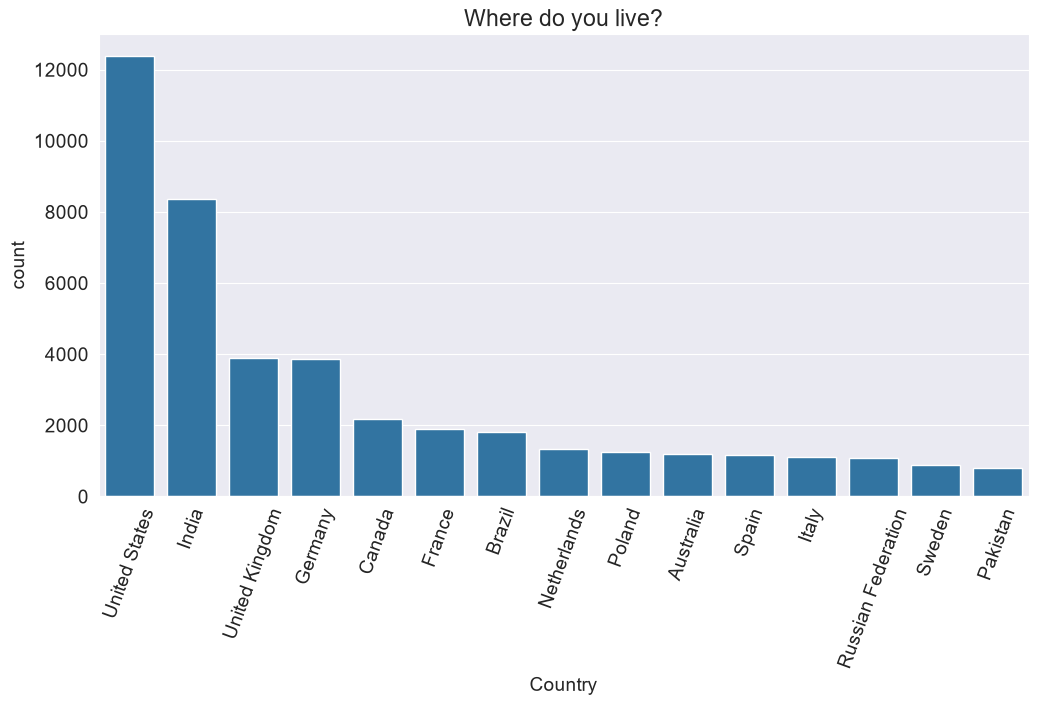

In [231]:
plt.figure(figsize=(12, 6))
plt.xticks(rotation=70)
plt.title(schema.Country)
sns.barplot(x=top_countries.index, y=top_countries)
plt.show()

It appears that a disproportionately high number of respondents are from the US and India, probably because the survey is in English, and these countries have the highest English-speaking populations. We can already see that the survey may not be representative of the global programming community - especially from non-English speaking countries. Programmers from non-English speaking countries are almost certainly underrepresented.

#### Age
The distribution of respondents' age is another crucial factor to look at. We can use a histogram to visualize it.

(array([  209.,  2419.,  9135., 11938.,  8739.,  5582.,  3031.,  1756.,
         1038.,   622.,   333.,   143.,    75.]),
 array([10., 15., 20., 25., 30., 35., 40., 45., 50., 55., 60., 65., 70.,
        75.]),
 <BarContainer object of 13 artists>)

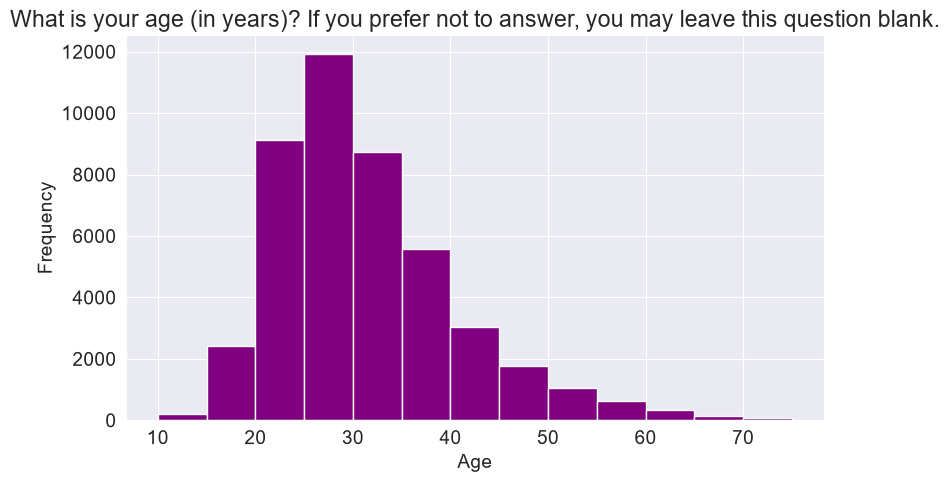

In [232]:
plt.title(schema.Age)
plt.xlabel('Age')
sns.histplot()
plt.ylabel('Frequency')
plt.hist(survey_df.Age, bins=np.arange(10,80,5), color = 'purple')


It appears that a large percentage of respondents are 20-45 years old. It's somewhat representative of the programming community in general. Many young people have taken up computer science as their field of study or profession in the last 20 years.

In [282]:
survey_df['less than 10 years'] = survey_df['Age'] < 10
survey_df['10-18 years'] = (survey_df.Age < 18) & (survey_df.Age>=10)
survey_df['18-30 years'] = (survey_df.Age < 30) & (survey_df.Age>=18)
survey_df['30-45 years'] = (survey_df.Age < 45) & (survey_df.Age>=30)
survey_df['45-60 years'] = (survey_df.Age < 60) & (survey_df.Age>=45)


In [285]:

# option A: explicit comparison
#aa = survey_df[survey_df['less than 10 years'] == True]

# or simpler:
aa = survey_df[(survey_df['less than 10 years']) & (~survey_df['10-18 years']) & (survey_df['30-45 years'])]


# or option B: use the boolean column directly
#aa = survey_df[survey_df['less than 10 years']]

In [286]:
aa

,Country,Age,Gender,EdLevel,UndergradMajor,Hobbyist,Age1stCode,YearsCode,YearsCodePro,LanguageWorkedWith,...,WorkWeekHrs,JobSat,JobFactors,NEWOvertime,NEWEdImpt,less than 10 years,10-18 years,18-30 years,30-45 years,45-60 years


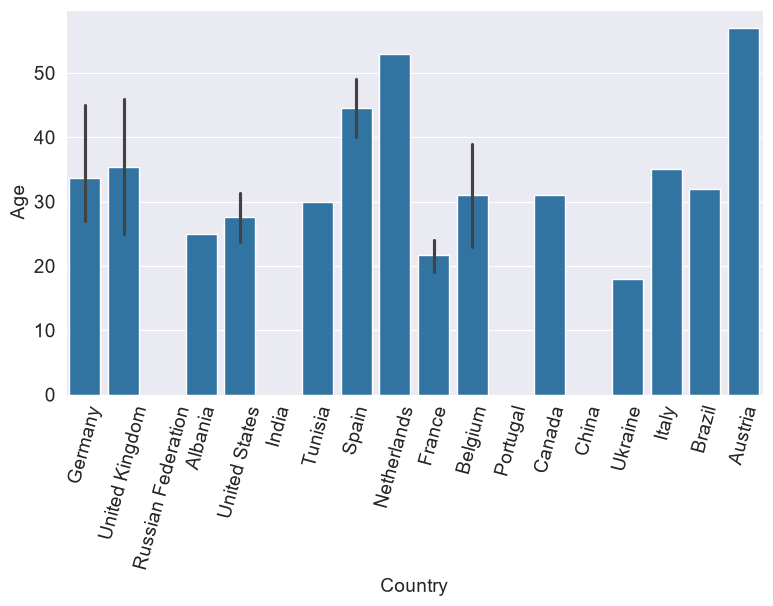

In [273]:
sns.barplot(x=survey_df['Country'].head(50), y =survey_df.Age)
plt.xticks(rotation = 75);

In [264]:
survey_df[survey_df['Country'] == 'India']

,Country,Age,Gender,EdLevel,UndergradMajor,Hobbyist,Age1stCode,YearsCode,YearsCodePro,LanguageWorkedWith,...,WorkWeekHrs,JobSat,JobFactors,NEWOvertime,NEWEdImpt,less than 10 years,10-18 years,18-30 years,30-45 years,45-60 years
6,India,NaN,NaN,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",Yes,18.0,6.0,4.0,C#;HTML/CSS;PHP,...,NaN,Very satisfied,NaN,Sometimes: 1-2 days per month but less than we...,Very important,False,False,False,False,False
21,India,NaN,Man,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",Yes,18.0,10.0,2.0,Java;Python,...,50.0,Slightly dissatisfied,NaN,Often: 1-2 days per week or more,Very important,False,False,False,False,False
57,India,NaN,NaN,NaN,Web development or web design,Yes,22.0,NaN,NaN,C#;JavaScript;SQL;TypeScript,...,NaN,Very satisfied,Family friendliness,Often: 1-2 days per week or more,Very important,False,False,False,False,False
62,India,21.0,Man,"Secondary school (e.g. American high school, G...",NaN,Yes,17.0,4.0,NaN,C;C++;HTML/CSS;Java;JavaScript;Python,...,NaN,NaN,Flex time or a flexible schedule;How widely us...,NaN,NaN,False,False,True,False,False
147,India,36.0,Man,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",Yes,31.0,5.0,3.0,Bash/Shell/PowerShell;C++;Perl,...,70.0,Very satisfied,"Languages, frameworks, and other technologies ...",Sometimes: 1-2 days per month but less than we...,Critically important,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64391,India,NaN,Man,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Computer science, computer engineering, or sof...",Yes,18.0,5.0,NaN,C;HTML/CSS;Java;JavaScript;PHP;Python;SQL,...,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False
64398,India,NaN,NaN,"Associate degree (A.A., A.S., etc.)",NaN,Yes,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False
64439,India,NaN,Man,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",I never declared a major,Yes,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False
64442,India,NaN,NaN,NaN,NaN,Yes,NaN,NaN,NaN,SQL,...,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False



#### Gender
Let's look at the distribution of responses for the Gender. It's a well-known fact that women and non-binary genders are underrepresented in the programming community, so we might expect to see a skewed distribution here.

In [265]:
schema.Gender

'Which of the following describe you, if any? Please check all that apply. If you prefer not to answer, you may leave this question blank.'

In [287]:
gender_counts = survey_df.Gender.value_counts()

In [288]:
gender_counts

Gender
Man                                                  45895
Woman                                                 3835
Non-binary, genderqueer, or gender non-conforming      385
Name: count, dtype: int64

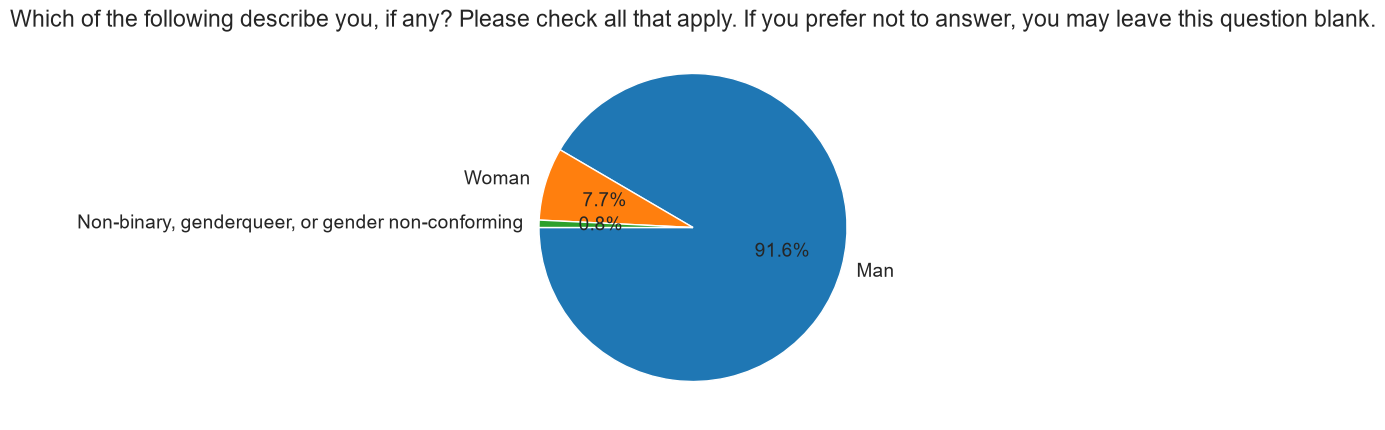

In [292]:
plt.Figure(figsize=(12,6));
plt.title(schema.Gender)
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=180,);

Only about 8% of survey respondents who have answered the question identify as women or non-binary. This number is lower than the overall percentage of women & non-binary genders in the programming community - which is estimated to be around 12%.

#### Education Level
Formal education in computer science is often considered an essential requirement for becoming a programmer. However, there are many free resources & tutorials available online to learn programming. Let's compare the education levels of respondents to gain some insight into this. We'll use a horizontal bar plot here.



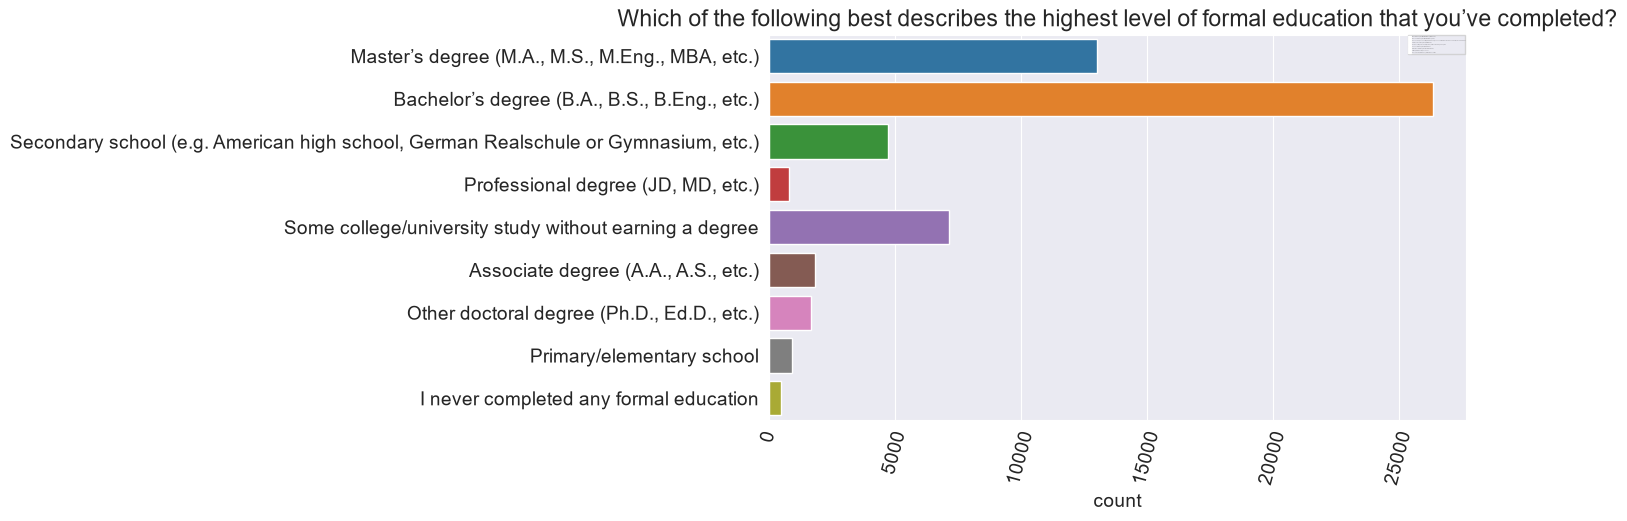

In [303]:
sns.countplot(y=survey_df.EdLevel, hue=survey_df.EdLevel);
plt.xticks(rotation = 75);
plt.title(schema.EdLevel);
plt.ylabel(None);
plt.legend(fontsize=0);


It appears that well over half of the respondents hold a bachelor's or master's degree, so most programmers seem to have some college education. However, it's not clear from this graph alone if they hold a degree in computer science.

Let's also plot undergraduate majors, but this time we'll convert the numbers into percentages and sort the values to make it easier to visualize the order.

In [304]:
schema.UndergradMajor

'What was your primary field of study?'

In [312]:
survey_df.UndergradMajor.value_counts() / survey_df.UndergradMajor.count()

UndergradMajor
Computer science, computer engineering, or software engineering                   0.619392
Another engineering discipline (such as civil, electrical, mechanical, etc.)      0.093542
Information systems, information technology, or system administration             0.079832
A natural science (such as biology, chemistry, physics, etc.)                     0.043166
Mathematics or statistics                                                         0.036271
Web development or web design                                                     0.035026
A business discipline (such as accounting, finance, marketing, etc.)              0.027006
A humanities discipline (such as literature, history, philosophy, etc.)           0.019696
A social science (such as anthropology, psychology, political science, etc.)      0.018215
Fine arts or performing arts (such as graphic design, music, studio art, etc.)    0.014125
I never declared a major                                                   

In [313]:
undergrad_pct = survey_df.UndergradMajor.value_counts() *100 / survey_df.UndergradMajor.count()

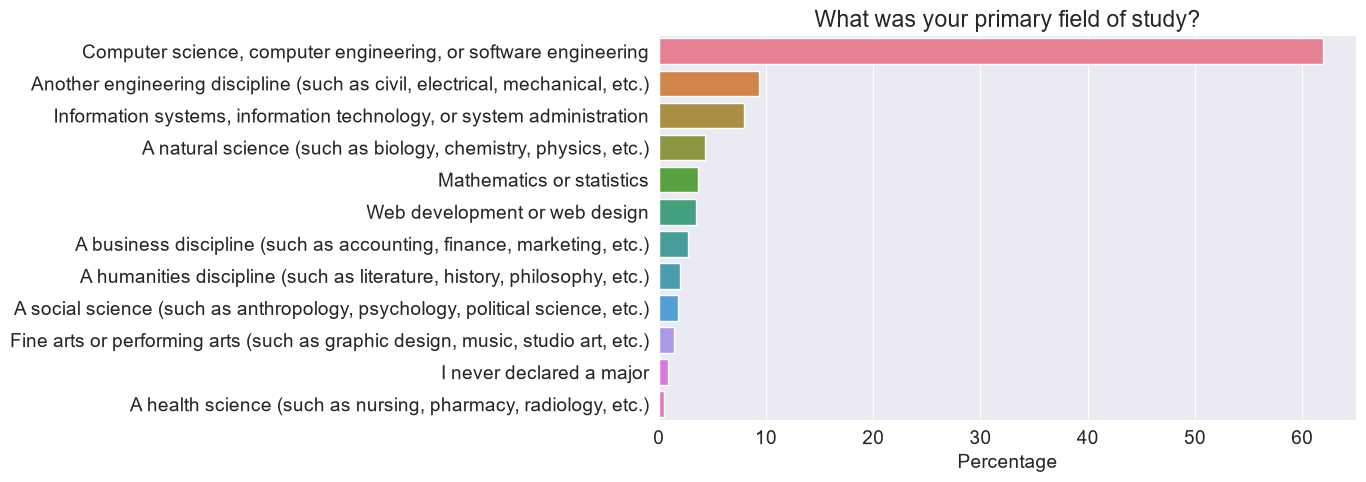

In [320]:

sns.barplot(x=undergrad_pct, y=undergrad_pct.index, hue=undergrad_pct.index)

plt.title(schema.UndergradMajor)
plt.ylabel(None);
plt.xlabel('Percentage');

It turns out that 40% of programmers holding a college degree have a field of study other than computer science - which is very encouraging. It seems to suggest that while a college education is helpful in general, you do not need to pursue a major in computer science to become a successful programmer.

### Employment
Freelancing or contract work is a common choice among programmers, so it would be interesting to compare the breakdown between full-time, part-time, and freelance work. Let's visualize the data from the Employment column.

In [321]:
schema.Employment

'Which of the following best describes your current employment status?'

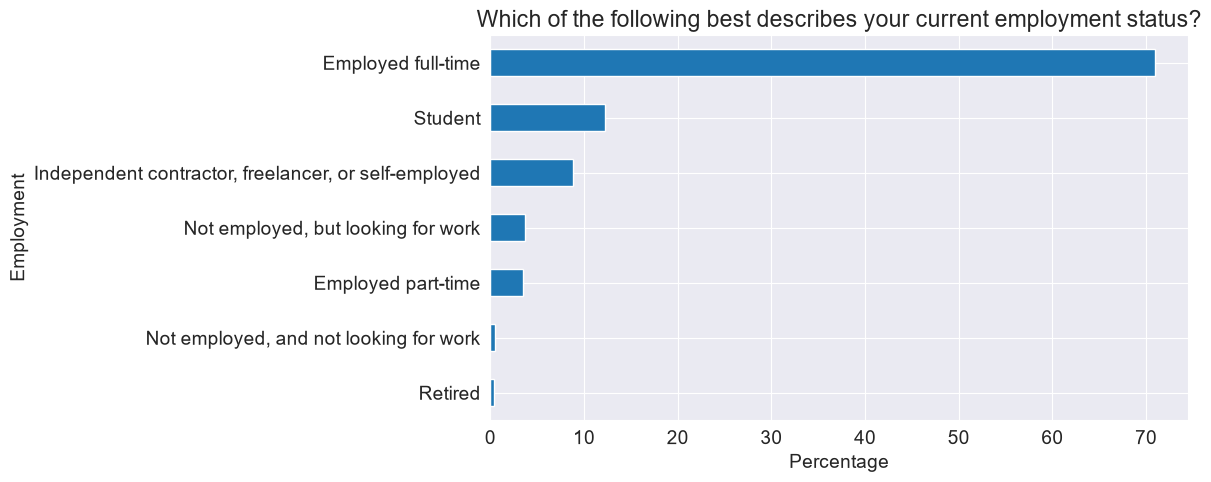

In [328]:
(survey_df.Employment.value_counts(normalize=True, ascending=True)*100).plot(kind='barh');
plt.title(schema.Employment);
plt.xlabel('Percentage');

The DevType field contains information about the roles held by respondents. Since the question allows multiple answers, the column contains lists of values separated by a semi-colon ;, making it a bit harder to analyze directly.

In [335]:
survey_df.DevType.value_counts()


DevType
Developer, full-stack                                                                                                                                                                                                                                                                                                                                                                                                 4396
Developer, back-end                                                                                                                                                                                                                                                                                                                                                                                                   3056
Developer, back-end;Developer, front-end;Developer, full-stack                                                                                                            

In [336]:
schema.DevType

'Which of the following describe you? Please select all that apply.'

Let's define a helper function that turns a column containing lists of values (like survey_df.DevType) into a data frame with one column for each possible option.

In [341]:
def split_multicolumn(col_series):
    result_df = col_series.to_frame()
    options = []
    # Iterate over the column
    for idx, value  in col_series[col_series.notnull()].iteritems():
        # Break each value into list of options
        for option in value.split(';'):
            # Add the option as a column to result
            if not option in result_df.columns:
                options.append(option)
                result_df[option] = False
            # Mark the value in the option column as True
            result_df.at[idx, option] = True
    return result_df[options]

In [342]:
def split_multicolumn(col_series):
    result_df = col_series.to_frame()
    options = []
    for idx, value in col_series.dropna().items():
        for option in value.split(';'):
            if option not in result_df.columns:
                options.append(option)
                result_df[option] = False
            result_df.at[idx, option] = True
    return result_df[options]

In [343]:
dev_type_df = split_multicolumn(survey_df.DevType)

In [346]:
dev_type_df

,"Developer, desktop or enterprise applications","Developer, full-stack","Developer, mobile",Designer,"Developer, front-end","Developer, back-end","Developer, QA or test",DevOps specialist,"Developer, game or graphics",Database administrator,...,System administrator,Engineering manager,Product manager,Data or business analyst,Academic researcher,Data scientist or machine learning specialist,Scientist,Senior executive/VP,"Engineer, site reliability",Marketing or sales professional
0,True,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,True,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64456,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
64457,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
64458,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
64459,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [347]:
dev_type_totals = dev_type_df.sum().sort_values(ascending=False)
dev_type_totals

Developer, back-end                              26996
Developer, full-stack                            26915
Developer, front-end                             18128
Developer, desktop or enterprise applications    11687
Developer, mobile                                 9406
DevOps specialist                                 5915
Database administrator                            5658
Designer                                          5262
System administrator                              5185
Developer, embedded applications or devices       4701
Data or business analyst                          3970
Data scientist or machine learning specialist     3939
Developer, QA or test                             3893
Engineer, data                                    3700
Academic researcher                               3502
Educator                                          2895
Developer, game or graphics                       2751
Engineering manager                               2699
Product ma